In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
import networkx as nx
font = {'size' : 15}
matplotlib.rc('font', **font)
plt.rcParams.update({
    "text.usetex": True,
    "font.family": "Helvetica"
})
from skimage import measure
from scipy.stats import binned_statistic
from numba import njit, jit
from numba.typed import List

In [10]:
#source_folder = "/data/biophys/schimmenti/earthquakes/MOKE_clusters/"
source_folder = "clusters_data/"
import os
os.makedirs("plots", exist_ok=True)

In [2]:
def get_clusters(edge_list,time_attr, dt, nodes=None, spatial_attr=None, ds=None):
    edge_mask = time_attr <= dt
    if(ds is not None):
        edge_mask = edge_mask*(spatial_attr <= ds)
    clusters_graph = nx.from_edgelist(edge_list[edge_mask], create_using=nx.DiGraph)
    if(nodes is not None):
        clusters_graph.add_nodes_from(nodes)
    return list(nx.weakly_connected_components(clusters_graph))

In [3]:
fields = [0.13, 0.14, 0.15, 0.16]
fields_colors = matplotlib.colormaps.get('tab10')(range(4))

In [4]:
def aggregate_clusters(time_values, xy_values, lengths, clusters):
    clusters_list = []
    for cluster in clusters:
        t_cluster = []
        x_cluster = []
        y_cluster = []
        #len_cluster = []
        for idx in cluster:
            x_cluster.append(xy_values[idx, :lengths[idx], 0])
            y_cluster.append(xy_values[idx, :lengths[idx], 1])
            t_cluster.append(time_values[idx]*np.ones(lengths[idx], dtype=int))
            #len_cluster.append(lengths[idx]*np.ones(lengths[idx], dtype=int))
        t_cluster = np.concatenate(t_cluster)
        x_cluster = np.concatenate(x_cluster)
        y_cluster = np.concatenate(y_cluster)
        #len_cluster = np.concatenate(len_cluster)
        clusters_list.append((t_cluster, x_cluster, y_cluster))
    return clusters_list

In [5]:
def growth_clusters(time_values, lengths, clusters):
    internal_cluster_time = []
    cluster_growth = []
    for cluster in clusters:
        t_cluster = time_values[np.array(list(cluster))]
        length_cluster = lengths[np.array(list(cluster))]
        t_cluster_sorted_indices = np.argsort(t_cluster)
        t_cluster_sorted = t_cluster[t_cluster_sorted_indices]
        length_cluster_sorted = length_cluster[t_cluster_sorted_indices]
        size_cluster_sorted = np.cumsum(length_cluster_sorted)
        t_cluster_shifted = t_cluster_sorted-t_cluster_sorted[0]
        internal_cluster_time.append(t_cluster_shifted)
        cluster_growth.append(size_cluster_sorted)
    return internal_cluster_time, cluster_growth

In [6]:
def get_cluster_sizes(aggr_clusters):
    sizes = []
    for cluster in aggr_clusters:
        cluster_times = cluster[0]
        cluster_x = cluster[1]
        cluster_y = cluster[2]
        sizes.append(len(cluster_times))
    return np.array(sizes)

In [7]:
def find_kolton_clusters(time_values, xy_values, lengths, window_length, d_max):
    clustered = {idx : False for idx, t in enumerate(time_values)}
    clusters = []
    for idx, t in enumerate(time_values):
        if(clustered[idx]):
            continue
        clustered[idx] = True
        cluster = {idx}
        x_t = xy_values[idx,:lengths[idx],0]
        y_t = xy_values[idx,:lengths[idx],1]
        for internal_idx,s in enumerate(time_values[idx+1:]):
            if((s-t) > window_length):
                break
            jdx = internal_idx + idx + 1
            if(clustered[jdx]):
                continue
            
            x_s = xy_values[jdx,:lengths[jdx],0]
            y_s = xy_values[jdx,:lengths[jdx],1]
            min_d = np.min(np.abs(x_t[:,None]-x_s[None,:])+np.abs(y_t[:,None]-y_s[None,:]))
            if(min_d <= d_max):
                clustered[jdx] = True
                cluster.add(jdx)
        clusters.append(cluster)
    return clusters

### Growth

In [8]:
dt = 10
internal_time_dict = {}
cluster_growth_dict = {}

for color, field in zip(fields_colors, fields):
    print(field)
    cluster_data = np.load("%sclusters_field=%1.2f.npz" % (source_folder,field))
    time_values, xy_values, lengths, edge_list, time_attr, spatial_attr = cluster_data['time_values'], cluster_data['xy_values'], cluster_data['lengths'],cluster_data['edge_list'], cluster_data['time_attr'], cluster_data['spatial_attr']
    
    edge_mask = time_attr <= dt
    clusters = get_clusters(edge_list, time_attr, dt, np.arange(len(time_values)))
    clusters_list = aggregate_clusters(time_values, xy_values, lengths, clusters)
    sizes = get_cluster_sizes(clusters_list)

    internal_time, cluster_growth = growth_clusters(time_values, lengths, clusters)
    internal_time_dict[field] = internal_time
    cluster_growth_dict[field] = cluster_growth

0.13
0.14
0.15
0.16


In [ ]:
for color, field in zip(fields_colors, fields):
    internal_time = internal_time_dict[field]
    cluster_growth = cluster_growth_dict[field]
    hist_3, edges,_ = binned_statistic(np.concatenate(internal_time), np.concatenate(cluster_growth)**3, bins=np.logspace(0,2))
    hist_2, edges,_ = binned_statistic(np.concatenate(internal_time), np.concatenate(cluster_growth)**2, bins=np.logspace(0,2))
    plt.scatter(edges[:-1],(hist_3/hist_2)**(-1.36), color=color, label="$H=%1.2f$" % field)
plt.legend()
plt.xscale('log')
plt.yscale('log')

### Number of clusters

0.13
0.14
0.15
0.16


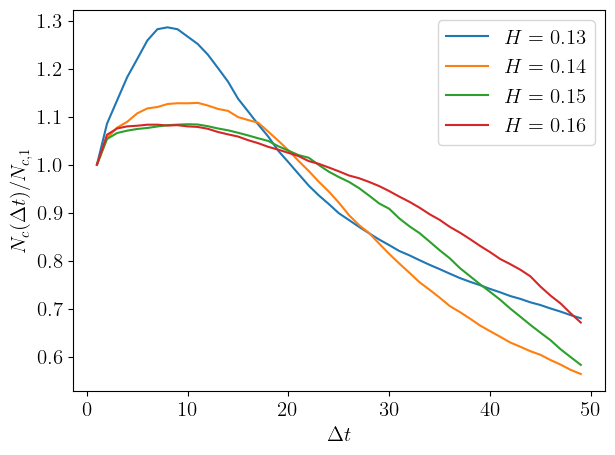

In [13]:
for color, field in zip(fields_colors, fields):
    print(field)
    cluster_data = np.load("%sclusters_field=%1.2f.npz" % (source_folder,field))
    time_values, xy_values, lengths, edge_list, time_attr, spatial_attr = cluster_data['time_values'], cluster_data['xy_values'], cluster_data['lengths'],cluster_data['edge_list'], cluster_data['time_attr'], cluster_data['spatial_attr']
    maximal_time = time_attr.max()
    clusters_maximal_times = np.arange(1, maximal_time)
    n_clusters = []
    for dt in clusters_maximal_times:
        cluster_set = get_clusters(edge_list, time_attr, dt, np.arange(len(time_values)))
        n_clusters.append(len(cluster_set))
    n_clusters = np.array(n_clusters)
    plt.plot(clusters_maximal_times,n_clusters/n_clusters[0], color=color, label="$H=%1.2f$" % field)
plt.xlabel("$\\Delta t$")
plt.ylabel("$N_c(\\Delta t) / N_{c,1}$")
plt.legend()
plt.tight_layout()
plt.savefig("plots/num_clusters_dt.pdf", bbox_inches='tight')
plt.show()

### Plots

In [14]:
def filter_edgelist(edge_list, nodes_to_keep):
    mask_to_keep = np.isin(edge_list[:,0], nodes_to_keep)*np.isin(edge_list[:,1], nodes_to_keep)
    return mask_to_keep

0.13
0.14
0.15
0.16


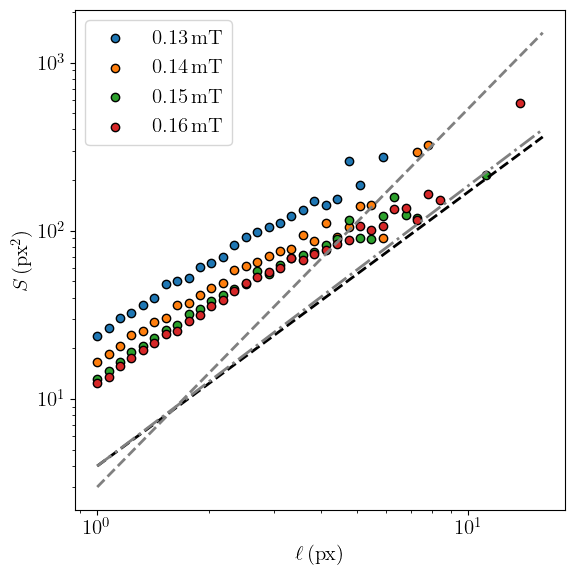

In [43]:
dt = 6
t0 = 10000
plot_type = "scale"
log_limits = {"size" : (0,2.5), "length" : (0, 1.3), "scale" : (0,1.2)}
the_bins = np.logspace(log_limits[plot_type][0],log_limits[plot_type][1],40)
theory = {
    "size" : [("qKPZ", 1.25, 0.5, "black", "dashed"), ("qEW", 1.11, 0.5, "grey", "dashed"), ("equil.", 0.8, 1e-2,  "grey", "dashdot")  ],
    "length" : [("qKPZ", 1.42, 0.8, "black", "dashed"), ("qEW", 1.26, 0.8, "grey", "dashed"), ("equil.", 2/3, 1e-2,  "grey", "dashdot")  ],
    "scale" : [("qKPZ", -(1+0.63), 4.0, "black", "dashed"), ("qEW", -(1+1.25), 3.0, "grey", "dashed"), ("equil.", -(1+2.0/3.0), 4.0,  "grey", "dashdot")  ]
}
labels = {
    "size" : ("$S \\, (\\rm{px}^2)$",  "$P(S)$", "$S \\, (\\mu\\rm{m}^2)$"),
    "length" : ("$\\ell \\, (\\rm{px})$",  "$P(\\ell)$", "$\\ell \\, (\\mu\\rm{m})$"),
    "scale" : ("$\\ell \\, (\\rm{px})$",  "$S \\, (\\rm{px}^2)$", "$\\ell \\, (\\mu\\rm{m})$", "$S \\, (\\mu\\rm{m}^2)$"),
}
if(plot_type == "scale"):
    fig = plt.figure(figsize=(6,6))
else:
    fig = plt.figure(figsize=(6,4))
for color, field in zip(fields_colors, fields):
    print(field)
    cluster_data = np.load("%sclusters_field=%1.2f.npz" % (source_folder,field))
    time_values, xy_values, lengths, edge_list, time_attr, spatial_attr = cluster_data['time_values'], cluster_data['xy_values'], cluster_data['lengths'],cluster_data['edge_list'], cluster_data['time_attr'], cluster_data['spatial_attr']
    nodes_to_keep = np.argwhere(time_values > t0).flatten()
    mask_to_keep = filter_edgelist(edge_list,nodes_to_keep )
    clusters = get_clusters(edge_list[mask_to_keep,:], time_attr[mask_to_keep], dt, nodes_to_keep)
    clusters_list = aggregate_clusters(time_values, xy_values, lengths, clusters)
    clusters_cov = np.array([np.cov(np.concatenate([c[1][:,None], c[2][:,None]], axis=1), rowvar=False, bias=True) if len(c[1])>1 else np.zeros((2,2)) for c in clusters_list ])
    cc_vals = np.linalg.eigh(clusters_cov).eigenvalues
    cc_dets = np.prod(cc_vals, axis=1)
    cc_dets[cc_dets < 0] = 0
    sizes = get_cluster_sizes(clusters_list)
    scaling_factor = np.median(np.sqrt(np.sqrt(cc_dets[cc_dets>0])/sizes[cc_dets>0]))
    elongation = np.sqrt(cc_vals[:, 1])*scaling_factor
    
    if(plot_type == "size"):
        hist, edges = np.histogram(sizes, density=True, bins=the_bins)
    elif(plot_type == "length"):
        hist, edges = np.histogram(elongation, density=True, bins=the_bins)
    elif(plot_type == "scale"):
        hist, edges, _ = binned_statistic(elongation, sizes, bins=the_bins)
    plt.scatter(edges[:-1], hist,color=color, edgecolors='black', label="$%1.2f \\, \\rm{mT}$" % field)
for style in theory[plot_type]:
    plt.plot(the_bins, style[2]*the_bins**(-style[1]),  ls=style[4], color=style[3], lw=2)
ax = plt.gca()
ax.set_ylabel(labels[plot_type][1])
ax.set_xlabel(labels[plot_type][0], )
if(plot_type == "scale"):
    ax.legend()
else:
    ax.legend(loc='lower left')
ax.set_xscale('log')
ax.set_yscale('log')
ylims = ax.get_ylim()
xlims = ax.get_xlim()
if(plot_type == "size"):
    twiny = plt.gca().twiny()
    twiny.set_xscale('log')
    twiny.set_yscale('log')
    twiny.plot(the_bins*0.4*0.4, the_bins*0.4*0.4, alpha=0.0)
    twiny.set_xlabel(labels[plot_type][2])
    twiny.set_ylim(ylims)
if(plot_type == "length"):
    twiny = plt.gca().twiny()
    twiny.set_xscale('log')
    twiny.set_yscale('log')
    twiny.plot(the_bins*0.4, the_bins*0.4, alpha=0.0)
    twiny.set_xlabel(labels[plot_type][2])
    twiny.set_ylim(ylims)
#if(plot_type == "scale"):
#    twin = plt.gca().twiny().twinx()
#    twin.set_xscale('log')
#    twin.set_yscale('log')
#    twin.plot(the_bins*0.4, the_bins*0.4*0.4, alpha=0.0)
#    #twin.set_ylim(ylims)
#    #twin.set_xlim(xlims)
plt.tight_layout()
plt.savefig("plots/%s.pdf" % plot_type, bbox_inches='tight')
plt.show()

### Observables

In [ ]:
dt = 10
dt_kolton = 3
for color, field in zip(fields_colors, fields):
    print(field)
    cluster_data = np.load("%sclusters_field=%1.2f.npz" % (source_folder,field))
    time_values, xy_values, lengths, edge_list, time_attr, spatial_attr = cluster_data['time_values'], cluster_data['xy_values'], cluster_data['lengths'],cluster_data['edge_list'], cluster_data['time_attr'], cluster_data['spatial_attr']
    
    clusters = get_clusters(edge_list, time_attr, dt, np.arange(len(time_values)))
    clusters_list = aggregate_clusters(time_values, xy_values, lengths, clusters)
    sizes = get_cluster_sizes(clusters_list)
    
    fig, ax = plt.subplots(figsize=(14,4), ncols=2)
    dt_kolton = 3
   
    kolton_clusters = find_kolton_clusters(time_values, xy_values, lengths, window_length=dt_kolton, d_max=2)
    kolton_clusters_list = aggregate_clusters(time_values, xy_values, lengths, kolton_clusters)
    kolton_sizes = get_cluster_sizes(kolton_clusters_list)
    hist, edges = np.histogram(kolton_sizes, density=True, bins=np.logspace(0,2.5,40))
    ax[0].scatter(edges[:-1], hist, label='PRB2018 Approach $\\Delta t=%1.2f$ s' % (0.2*dt_kolton), color='violet', marker='s', edgecolors='black')
    for dt_kolton, k_color  in zip([3, 6, 12], ['violet', 'yellow', 'brown']):
        kolton_clusters = find_kolton_clusters(time_values, xy_values, lengths, window_length=dt_kolton, d_max=2)
        kolton_clusters_list = aggregate_clusters(time_values, xy_values, lengths, kolton_clusters)
        kolton_sizes = get_cluster_sizes(kolton_clusters_list)
        hist, edges = np.histogram(kolton_sizes, density=True, bins=np.logspace(0,2.5,40))
        ax[1].scatter(edges[:-1], hist, label='PRB2018 Approach $\\Delta t=%1.2f$ s' % (0.2*dt_kolton), color=k_color, marker='s', edgecolors='black')
    hist, edges = np.histogram(sizes, density=True, bins=np.logspace(0,2.5,40))
    ax[0].scatter(edges[:-1], hist, label='Our approach', color=color, edgecolors='black')
    ax[0].set_xscale('log')
    ax[0].set_yscale('log')
    ax[0].set_xlabel("$S \quad [ \\rm{pixel}^2 ]$")
    ax[0].set_ylabel("$P(S)$")
    ax[1].set_xscale('log')
    ax[1].set_yscale('log')
    ax[1].set_xlabel("$S \quad [ \\rm{pixel}^2 ]$")
    ax[1].set_ylabel("$P(S)$")
    #plt.plot(np.logspace(0.2,2.5), 0.8*np.logspace(0.2,2.5)**(-1.26), ls='dashed', color='black', lw=2)
    #plt.plot(np.logspace(0.2,2.5), 0.2*np.logspace(0.2,2.5)**(-1.11), ls='dashed', color='grey', lw=2)
    #plt.plot(np.logspace(0.2,2.5), 1e-2*np.logspace(0.2,2.5)**(-0.8), ls='-.', color='grey', lw=2)
    ax[0].legend()
    ax[1].legend(fontsize=10)
    plt.suptitle("$H=%1.2f$" % field)
    
    #ax[0].set_aspect(0.3)
    #ax[1].set_aspect(0.3)
    #plt.tight_layout()
    plt.savefig("plots/s_comparison_kolton_field=%1.2f_dt=%i.pdf" % (field,dt), bbox_inches='tight')
    plt.show()

In [ ]:
dt = 10
dt_kolton = 3
for color, field in zip(fields_colors, fields):
    print(field)
    cluster_data = np.load("%sclusters_field=%1.2f.npz" % (source_folder,field))
    time_values, xy_values, lengths, edge_list, time_attr, spatial_attr = cluster_data['time_values'], cluster_data['xy_values'], cluster_data['lengths'],cluster_data['edge_list'], cluster_data['time_attr'], cluster_data['spatial_attr']
    
    clusters = get_clusters(edge_list, time_attr, dt, np.arange(len(time_values)))
    clusters_list = aggregate_clusters(time_values, xy_values, lengths, clusters)
    sizes = get_cluster_sizes(clusters_list)
    hist, edges = np.histogram(sizes, density=True, bins=np.logspace(0,2.5,40))
    plt.scatter(edges[:-1], hist, label='Our approach', color=color, edgecolors='black')


    kolton_clusters = find_kolton_clusters(time_values, xy_values, lengths, window_length=dt_kolton, d_max=2)
    kolton_clusters_list = aggregate_clusters(time_values, xy_values, lengths, kolton_clusters)
    kolton_sizes = get_cluster_sizes(kolton_clusters_list)
    hist, edges = np.histogram(kolton_sizes, density=True, bins=np.logspace(0,2.5,40))
    plt.scatter(edges[:-1], hist, label='PRB2018 Approach $\\Delta t=%1.2f$ s' % (0.2*dt_kolton), color='violet', marker='s', edgecolors='black')
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel("$S \quad [ \\rm{pixel}^2 ]$")
    plt.ylabel("$P(S)$")
    #plt.plot(np.logspace(0.2,2.5), 0.8*np.logspace(0.2,2.5)**(-1.26), ls='dashed', color='black', lw=2)
    #plt.plot(np.logspace(0.2,2.5), 0.2*np.logspace(0.2,2.5)**(-1.11), ls='dashed', color='grey', lw=2)
    #plt.plot(np.logspace(0.2,2.5), 1e-2*np.logspace(0.2,2.5)**(-0.8), ls='-.', color='grey', lw=2)
    plt.legend()
    plt.title("$H=%1.2f$" % field)
    
    plt.gca().set_aspect(0.3)
    plt.tight_layout()
    plt.savefig("plots/s_comparison_kolton_field=%1.2f_dt=%i_dt_k=%i.pdf" % (field,dt, dt_kolton))
    plt.show()

### Correlation functions

In [ ]:
def segment_noevents(data, no_event_val=-1):
    no_event_regions = [ r.astype('int') for r in measure.find_contours(data,no_event_val)]
    no_event_regions_sizes = np.array([r.shape[0] for r in no_event_regions])
    sorted_regions_idx = np.argsort(no_event_regions_sizes)
    inner_region = no_event_regions[sorted_regions_idx[-2]]
    outer_region = no_event_regions[sorted_regions_idx[-1]]
    center = inner_region.mean(axis=0)
    return inner_region,  outer_region, center

In [ ]:
@njit
def angular_corr(times, angles, max_time):
    delta_times = []
    delta_angles = []
    for i, (t_i, a_i) in enumerate(zip(times, angles)):
        for t_j, a_j in zip(times[i+1:], angles[i+1:]):
            dt_ji = t_j - t_i
            if(dt_ji > max_time):
                break
            delta_times.append(float(dt_ji))
            da_ji = np.arccos(np.cos(a_j-a_i))
            
            delta_angles.append(da_ji)
    return delta_times, delta_angles

In [ ]:
corr_times_angles = {}
for color,field in zip( fields_colors, fields):
  cluster_data = np.load("%sclusters_field=%1.2f.npz" % (source_folder,field))
  time_values, xy_values, lengths, edge_list, time_attr, spatial_attr = cluster_data['time_values'], cluster_data['xy_values'], cluster_data['lengths'],cluster_data['edge_list'], cluster_data['time_attr'], cluster_data['spatial_attr']
  file_name = "data/file_field%1.2f.csv" % field
  img_data = np.loadtxt(file_name, delimiter=',').astype('int')
  inner_region, outer_region, center = segment_noevents(img_data)
  events_r = []
  events_theta = []
  events_init_times = []
  for (t_i, xy_i, l_i) in zip(time_values, xy_values, lengths):
    centroid_x, centroid_y = np.mean(xy_i[:l_i, 0]), np.mean(xy_i[:l_i,1])
    init_time = t_i
    events_init_times.append(float(init_time))
    events_r.append(np.sqrt((centroid_x-center[0])**2+(centroid_y-center[1])**2))
    events_theta.append(np.arctan2(centroid_x-center[0], centroid_y-center[1]))
  events_init_times = np.array(events_init_times)
  events_r = np.array(events_r)
  events_theta = np.pi+np.array(events_theta)
  print("Correlating...")
  #ththp = np.arccos(np.cos(events_theta[:,None]-events_theta[None,:]))
  #ththp = np.minimum(ththp, 2*np.pi-ththp)
  #ttp = events_init_times[:,None]-events_init_times[None,:]
  #ttp_mask = ttp > 0
  ttp, ththp = angular_corr(events_init_times,events_theta, 10000)
  print(len(ttp))
  ttp = np.array(ttp)
  ththp =np.array(ththp)
  print("Done...")
  corr_times_angles[field] = (ttp, ththp)

In [ ]:
operation = 'var'
for color,field in zip( fields_colors, fields):
  if(operation == 'mean'):
    op = 'mean'
  else:
    op = np.var
    op = lambda x : np.mean(x**2)
  ttp, ththp = corr_times_angles[field]
  hist, edges, _ = binned_statistic(ttp, ththp, bins=np.logspace(1, 4,), statistic=op)
  plt.plot(0.2*edges[:-1], hist, color=color, lw=3)
  
  if(operation == 'mean'):
    plt.hlines( np.pi/2, 0.2*edges[0], 0.2*edges[-1], label='$\delta \\theta^2 = \pi/2$', color='black', ls='-.' )
    plt.ylim(1.2, plt.gca().get_ylim()[1])
    plt.ylabel("$\\langle \delta \\theta \\rangle$")
  else:
    plt.hlines( np.pi*np.pi/3 , 0.2*edges[0], 0.2*edges[-1], label='$\delta \\theta^2 = \pi^2/3$', color='black', ls='-.' )
    plt.ylim(2.5, plt.gca().get_ylim()[1])
    plt.legend(loc='lower right')
    plt.ylabel("$\\langle \delta \\theta ^2 \\rangle$")
  plt.xscale('log')
  #plt.xlim(0.2, plt.gca().get_xlim()[1])
  plt.title("$H=%1.2f$" % field)
  
  plt.xlabel("$\\tau$ (s)")
  
  plt.savefig("plots/ang_corr_%s_frames_field=%1.2f.pdf" % (operation,field))
  plt.show()

In [ ]:
dt = 10
dt_kolton = 3
for color,field in zip( fields_colors, fields):
  cluster_data = np.load("%sclusters_field=%1.2f.npz" % (source_folder,field))
  time_values, xy_values, lengths, edge_list, time_attr, spatial_attr = cluster_data['time_values'], cluster_data['xy_values'], cluster_data['lengths'],cluster_data['edge_list'], cluster_data['time_attr'], cluster_data['spatial_attr']
  
  for option, style in zip(['Us', 'PRB2018'], ['-','dashed']):
    if(option == 'Us'):
      clusters = get_clusters(edge_list, time_attr, dt, np.arange(len(time_values)))
      clusters_list = aggregate_clusters(time_values, xy_values, lengths, clusters)
      sizes = get_cluster_sizes(clusters_list)
    else:
      continue
      clusters = find_kolton_clusters(time_values, xy_values, lengths, window_length=dt_kolton, d_max=4)
      clusters_list = aggregate_clusters(time_values, xy_values, lengths, clusters)
      sizes = get_cluster_sizes(clusters_list)
    file_name = "data/file_field%1.2f.csv" % field
    img_data = np.loadtxt(file_name, delimiter=',').astype('int')
    inner_region, outer_region, center = segment_noevents(img_data)
    clusters_r = []
    clusters_theta = []
    clusters_init_times = []
    for cluster in clusters_list:
      centroid_x, centroid_y = np.mean(cluster[1]), np.mean(cluster[2])
      init_time = np.min(cluster[0])
      clusters_init_times.append(init_time)
      clusters_r.append(np.sqrt((centroid_x-center[0])**2+(centroid_y-center[1])**2))
      clusters_theta.append(np.arctan2(centroid_x-center[0], centroid_y-center[1]))
    clusters_init_times = np.array(clusters_init_times)
    clusters_r = np.array(clusters_r)
    clusters_theta = np.pi+np.array(clusters_theta)
    ththp = np.arccos(np.cos(clusters_theta[:,None]-clusters_theta[None,:]))
    #ththp = np.minimum(ththp, 2*np.pi-ththp)
    ttp = clusters_init_times[:,None]-clusters_init_times[None,:]
    ttp_mask = ttp > 0
    hist, edges, _ = binned_statistic(ttp[ttp_mask], ththp[ttp_mask], bins=np.logspace(0, 5.3), statistic='mean')
    plt.plot(0.2*(edges[:-1]+edges[1:])/2, hist, color=color, ls=style, label=option)
  plt.hlines( np.pi/2 , 0.2*edges[0], 0.2*edges[-1], label='Uncorrelated separation', color='black', ls='-.' )
  plt.title("$H=%1.2f$" % field)
  plt.legend()
  plt.xlabel("$\\tau$ (s)")
  plt.ylabel("$\\langle \\theta(t+\\tau)-\\theta(t) \\rangle$")
  plt.xscale('log')
  plt.savefig("plots/ang_corr_kolton_field=%1.2f_dt=%i_dt_k=%i.pdf" % (field,dt, dt_kolton))
  plt.show()